# 05 — Validation against the real batteries

The model is only worth believing if it can reproduce what the batteries that actually exist have earned. This notebook rebuilds each SWIS battery's revenue from first principles — SCADA, enablement schedules, clearing prices and loss factors — and sets it beside what the model says a battery of the same size could have earned over the same days.

Three outcomes are possible, and only one of them is good:

* the model's **realisable** figure is close to or below what real batteries achieved — the model is a usable floor;
* the model comfortably beats every real battery — a constraint is missing, or operators are optimising for something the model does not represent;
* real batteries beat the model's **perfect-foresight bound** — the model is wrong, because that bound cannot be beaten.

The model is never tuned to close a gap. Gaps are diagnosed and written up.

Compute: `scripts/run_backcast.py` writes the outputs this notebook reads.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if str(Path.cwd().parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

from src import backcast, data, viz
from src.model import SERVICES
from src.paths import OUTPUTS

viz.use_style()
pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 60)

RECOMPUTE = False  # set True for a cold run; takes roughly 40 minutes

if RECOMPUTE or not (OUTPUTS / "backcast_summary.csv").exists():
    subprocess.run([sys.executable, "scripts/run_backcast.py"], cwd=Path.cwd().parent, check=True)

summary = pd.read_csv(OUTPUTS / "backcast_summary.csv", index_col=0)
daily = pd.read_parquet(OUTPUTS / "backcast_daily.parquet")
daily["trading_date"] = pd.to_datetime(daily["trading_date"])
comparison = pd.read_csv(OUTPUTS / "backcast_model_comparison.csv", index_col=0)
fcess_by_year = pd.read_csv(OUTPUTS / "backcast_fcess_by_year.csv", index_col=0)

print(f"{len(summary)} storage facilities, {len(daily):,} facility-days")

8 storage facilities, 4,276 facility-days


## The fleet

Registered MW in the public standing data is a connection-point figure and can exceed what a facility ever injects, so the observed peak is used as the rating. Usable energy is taken from the Capacity Credits the facility holds, inverted through the accreditation rule (assumption C1); the largest sustained discharge seen in SCADA is kept as a lower-bound cross-check, because a battery is not obliged to discharge fully in one unbroken run and in practice rarely does.

In [2]:
fleet_view = summary[
    [
        "registered_mw",
        "observed_peak_mw",
        "usable_mwh",
        "duration_h",
        "duration_source",
        "first_full_month",
        "days",
    ]
]
fleet_view.round(2)

,registered_mw,observed_peak_mw,usable_mwh,duration_h,duration_source,first_full_month,days
facility_code,,,,,,,
ALINTA_WGP_ESR1,200.0,100.96,211.91,2.10,inverted from Capacity Credits,2026-08,93
COLLIE_BESS2,600.0,300.06,1279.32,4.26,inverted from Capacity Credits,2025-08,458
COLLIE_ESR1,400.0,199.98,852.88,4.26,inverted from Capacity Credits,2024-10,756
COLLIE_ESR4,500.0,252.00,1066.10,4.23,inverted from Capacity Credits,2026-01,305
COLLIE_ESR5,500.0,252.70,1066.10,4.22,inverted from Capacity Credits,2026-01,305
KWINANA_ESR1,200.0,100.67,197.23,1.96,inverted from Capacity Credits,2024-01,1036
KWINANA_ESR2,450.0,226.36,959.49,4.24,inverted from Capacity Credits,2025-04,580
MERREDIN_ESR1,200.0,NaN,NaN,NaN,NaN,NaN,0


## Rebuilt revenue, per battery

Restricted to each facility's full operating months, so commissioning periods do not drag the per-MW figures down. Capacity revenue is shown separately because it is contracted rather than traded.

In [3]:
revenue_view = summary[
    [
        "observed_peak_mw",
        "duration_h",
        "days",
        "cycles_per_year",
        "energy_revenue",
        "fcess_revenue",
        "total_revenue",
        "revenue_per_mw_year",
        "revenue_per_mwh_year",
    ]
].copy()
for column in ("energy_revenue", "fcess_revenue", "total_revenue"):
    revenue_view[column] = revenue_view[column] / 1e6
revenue_view = revenue_view.rename(
    columns={c: f"{c} $m" for c in ("energy_revenue", "fcess_revenue", "total_revenue")}
)
revenue_view.round(2)

,observed_peak_mw,duration_h,days,cycles_per_year,energy_revenue $m,fcess_revenue $m,total_revenue $m,revenue_per_mw_year,revenue_per_mwh_year
facility_code,,,,,,,,,
ALINTA_WGP_ESR1,100.96,2.10,93,140.51,-0.09,0.00,-0.09,-3656.44,-1741.96
COLLIE_BESS2,300.06,4.26,458,204.22,13.11,0.22,13.33,35426.60,8309.20
COLLIE_ESR1,199.98,4.26,756,207.92,21.93,4.64,26.57,64194.68,15052.15
COLLIE_ESR4,252.00,4.23,305,251.54,-0.84,0.08,-0.76,-3615.38,-854.59
COLLIE_ESR5,252.70,4.22,305,280.07,-1.50,0.08,-1.42,-6740.72,-1597.74
KWINANA_ESR1,100.67,1.96,1036,517.38,6.39,24.81,31.20,109255.21,55765.39
KWINANA_ESR2,226.36,4.24,580,243.62,4.50,11.62,16.12,44847.00,10580.00
MERREDIN_ESR1,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
annual = daily.copy()
annual["year"] = annual["trading_date"].dt.year
by_year = annual.pivot_table(
    index="facility_code",
    columns="year",
    values="total_revenue",
    aggfunc="sum",
    observed=True,
)
print("total rebuilt revenue by calendar year, $ million")
(by_year / 1e6).round(2)

total rebuilt revenue by calendar year, $ million


year,2023,2024,2025,2026
facility_code,,,,
ALINTA_WGP_ESR1,NaN,NaN,NaN,-0.11
COLLIE_BESS2,NaN,NaN,7.37,6.36
COLLIE_ESR1,NaN,9.15,14.36,4.30
COLLIE_ESR4,NaN,NaN,0.44,-0.76
COLLIE_ESR5,NaN,NaN,0.15,-1.42
KWINANA_ESR1,0.56,19.49,12.04,-0.33
KWINANA_ESR2,NaN,0.41,14.66,2.28
MERREDIN_ESR1,NaN,NaN,NaN,-0.00


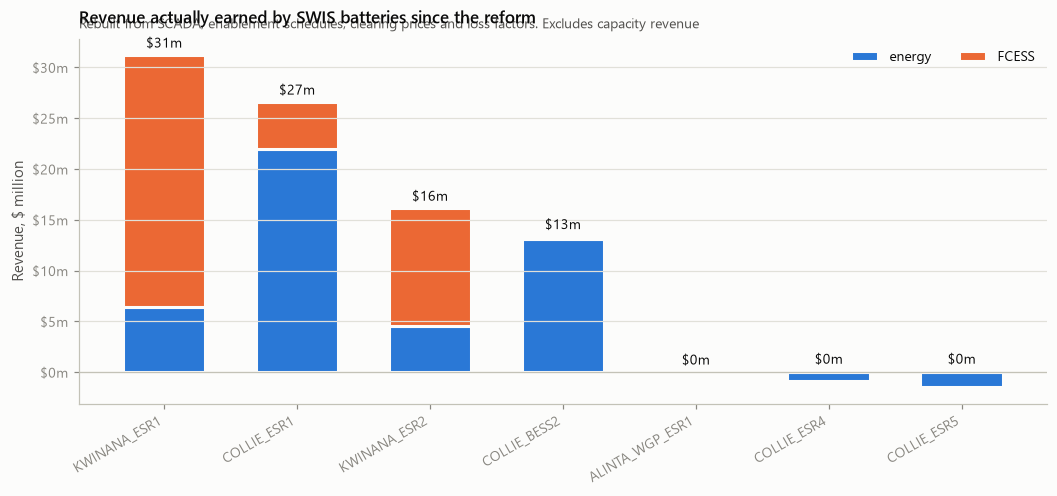

In [5]:
fig, ax = viz.figure(9.5, 4.4)

ordered = summary.sort_values("total_revenue", ascending=False)
ordered = ordered[ordered["days"] > 0]
x = np.arange(len(ordered))

energy = ordered["energy_revenue"] / 1e6
fcess = ordered["fcess_revenue"] / 1e6

ax.bar(x, energy, color=viz.SERIES[0], label="energy", width=0.62, linewidth=2, edgecolor=viz.SURFACE)
ax.bar(x, fcess, bottom=energy.clip(lower=0), color=viz.SERIES[1], label="FCESS", width=0.62, linewidth=2, edgecolor=viz.SURFACE)

for position, total in zip(x, (energy.clip(lower=0) + fcess)):
    ax.annotate(f"${total:,.0f}m", (position, total), textcoords="offset points",
                xytext=(0, 5), ha="center", fontsize=9, color=viz.INK_PRIMARY)

ax.axhline(0, color=viz.AXIS, linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(ordered.index, rotation=30, ha="right")
viz.money(ax, unit="m")
viz.finish(
    ax,
    "Revenue actually earned by SWIS batteries since the reform",
    subtitle="Rebuilt from SCADA, enablement schedules, clearing prices and loss factors. Excludes capacity revenue",
    ylabel="Revenue, $ million",
)
ax.legend(loc="upper right", ncols=2)
plt.show()

## Actual against modelled

For each battery the model is re-run at that battery's own rating, usable energy and FCESS accreditation, over exactly its operating days, with its own observed enablement as the ceiling. So the comparison tests dispatch skill, not market access.

In [6]:
view = comparison[
    [
        "days_compared",
        "actual_total",
        "model_perfect_foresight",
        "model_realisable",
        "actual_over_pf",
        "model_capture_rate",
    ]
].copy()
for column in ("actual_total", "model_perfect_foresight", "model_realisable"):
    view[column] = view[column] / 1e6
view.round(3)

,days_compared,actual_total,model_perfect_foresight,model_realisable,actual_over_pf,model_capture_rate
facility_code,,,,,,
ALINTA_WGP_ESR1,91,-0.094,1.469,-0.062,-0.064,-0.042
COLLIE_BESS2,452,13.179,32.445,9.080,0.406,0.280
COLLIE_ESR1,750,26.491,61.197,26.800,0.433,0.438
COLLIE_ESR4,301,-0.773,14.356,0.334,-0.054,0.023
COLLIE_ESR5,301,-1.399,14.392,0.326,-0.097,0.023
KWINANA_ESR1,1026,30.933,66.373,34.379,0.466,0.518
KWINANA_ESR2,574,15.999,44.254,20.180,0.362,0.456


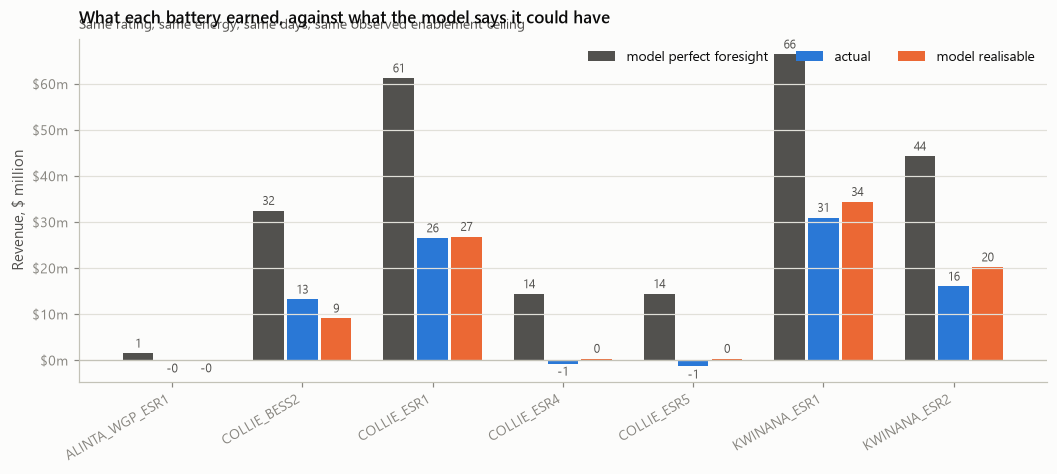

In [7]:
valid = comparison[comparison["model_perfect_foresight"] > 0].copy()

fig, ax = viz.figure(9.5, 4.2)
x = np.arange(len(valid))
width = 0.26

series = [
    ("model perfect foresight", valid["model_perfect_foresight"] / 1e6, viz.INK_SECONDARY),
    ("actual", valid["actual_total"] / 1e6, viz.SERIES[0]),
    ("model realisable", valid["model_realisable"] / 1e6, viz.SERIES[1]),
]
for slot, (label, values, colour) in enumerate(series):
    bars = ax.bar(x + (slot - 1) * width, values, width=width * 0.9, color=colour, label=label)
    ax.bar_label(bars, fmt="%.0f", padding=2, fontsize=8, color=viz.INK_SECONDARY)

ax.axhline(0, color=viz.AXIS, linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(valid.index, rotation=30, ha="right")
viz.money(ax, unit="m")
viz.finish(
    ax,
    "What each battery earned, against what the model says it could have",
    subtitle="Same rating, same energy, same days, same observed enablement ceiling",
    ylabel="Revenue, $ million",
)
ax.legend(loc="upper right", ncols=3)
plt.show()

In [8]:
violations = comparison[comparison["actual_over_pf"] > 1.0]
if len(violations):
    print("BOUND VIOLATED — a real battery earned more than perfect foresight says is possible:")
    print(violations[["actual_total", "model_perfect_foresight", "actual_over_pf"]].round(3))
else:
    print("no battery exceeded the perfect-foresight bound; the model is not understating the maximum")

print("\nactual revenue as a share of the perfect-foresight bound:")
print(comparison["actual_over_pf"].describe().round(3).to_string())

no battery exceeded the perfect-foresight bound; the model is not understating the maximum

actual revenue as a share of the perfect-foresight bound:
count    7.000
mean     0.207
std      0.263
min     -0.097
25%     -0.059
50%      0.362
75%      0.420
max      0.466


## Where the revenue came from

Splitting actual and modelled revenue into energy and FCESS says more than the totals do.

In [9]:
split = comparison[
    ["actual_energy", "actual_fcess", "model_pf_energy", "model_pf_fcess"]
].copy() / 1e6
split["energy capture"] = comparison["actual_energy"] / comparison["model_pf_energy"]
split["fcess capture"] = comparison["actual_fcess"] / comparison["model_pf_fcess"]
split.round(3)

,actual_energy,actual_fcess,model_pf_energy,model_pf_fcess,energy capture,fcess capture
facility_code,,,,,,
ALINTA_WGP_ESR1,-0.094,0.000,1.636,0.000,-0.057,NaN
COLLIE_BESS2,12.972,0.206,35.748,0.181,0.363,1.139
COLLIE_ESR1,21.868,4.623,61.172,4.337,0.357,1.066
COLLIE_ESR4,-0.850,0.077,16.065,0.074,-0.053,1.036
COLLIE_ESR5,-1.482,0.082,16.097,0.081,-0.092,1.017
KWINANA_ESR1,6.396,24.537,45.469,23.173,0.141,1.059
KWINANA_ESR2,4.561,11.438,36.946,10.713,0.123,1.068


## FCESS reconciliation

Modelled FCESS payments to storage, by calendar year. These are built from published enablement schedules and published clearing prices, so they should agree with AEMO's and the ERA's reported FCESS costs for the storage share. Any tolerance and the source checked are recorded in `docs/assumptions.md`.

In [10]:
print("modelled FCESS payments to SWIS storage, $ million")
(fcess_by_year / 1e6).round(2)

modelled FCESS payments to SWIS storage, $ million


,fcess_contingency_raise,fcess_contingency_lower,fcess_regulation_raise,fcess_regulation_lower,fcess_rocof,total
year,,,,,,
2023,0.00,0.00,0.00,0.00,0.0,0.00
2024,4.45,1.45,2.94,4.18,0.0,13.02
2025,9.41,6.10,4.32,4.25,0.0,24.07
2026,1.64,1.49,0.71,0.51,0.0,4.35


## Capacity revenue

Capacity Credits held, at the published Reserve Capacity Price for each capacity year (assumption C5). This is contracted revenue and does not depend on dispatch skill.

In [11]:
rows = []
for code in summary.index:
    frame = backcast.capacity_revenue(code)
    frame = frame[frame["capacity_year"].str[:4].astype(int).between(2023, 2026)]
    for row in frame.itertuples():
        rows.append(
            {
                "facility_code": code,
                "capacity_year": row.capacity_year,
                "credits_mw": row.capacity_credits_mw,
                "price_per_mw_year": row.reserve_capacity_price,
                "capacity_revenue_$m": (row.capacity_revenue or 0) / 1e6,
            }
        )
capacity = pd.DataFrame(rows)
capacity.pivot_table(
    index="facility_code", columns="capacity_year", values="capacity_revenue_$m", observed=True
).round(2)

capacity_year,2023-24,2024-25,2025-26,2026-27
facility_code,,,,
ALINTA_WGP_ESR1,NaN,NaN,0.00,10.49
COLLIE_BESS2,NaN,NaN,0.00,64.83
COLLIE_ESR1,NaN,0.00,50.28,41.58
COLLIE_ESR4,NaN,NaN,0.00,38.03
COLLIE_ESR5,NaN,NaN,0.00,37.89
KWINANA_ESR1,4.9,8.81,11.13,9.40
KWINANA_ESR2,NaN,NaN,0.00,48.62
MERREDIN_ESR1,NaN,NaN,0.00,20.42


## Revenue normalised

Per MW-year and per MWh-year, so facilities of different sizes and durations are comparable, and so the figures can be set beside the modelled 100 MW cases.

In [12]:
normalised = summary[summary["days"] > 0][
    ["observed_peak_mw", "duration_h", "revenue_per_mw_year", "revenue_per_mwh_year", "cycles_per_year"]
].sort_values("revenue_per_mw_year", ascending=False)
normalised.round(0)

,observed_peak_mw,duration_h,revenue_per_mw_year,revenue_per_mwh_year,cycles_per_year
facility_code,,,,,
KWINANA_ESR1,101.0,2.0,109255.0,55765.0,517.0
COLLIE_ESR1,200.0,4.0,64195.0,15052.0,208.0
KWINANA_ESR2,226.0,4.0,44847.0,10580.0,244.0
COLLIE_BESS2,300.0,4.0,35427.0,8309.0,204.0
COLLIE_ESR4,252.0,4.0,-3615.0,-855.0,252.0
ALINTA_WGP_ESR1,101.0,2.0,-3656.0,-1742.0,141.0
COLLIE_ESR5,253.0,4.0,-6741.0,-1598.0,280.0


## Monthly revenue through the period

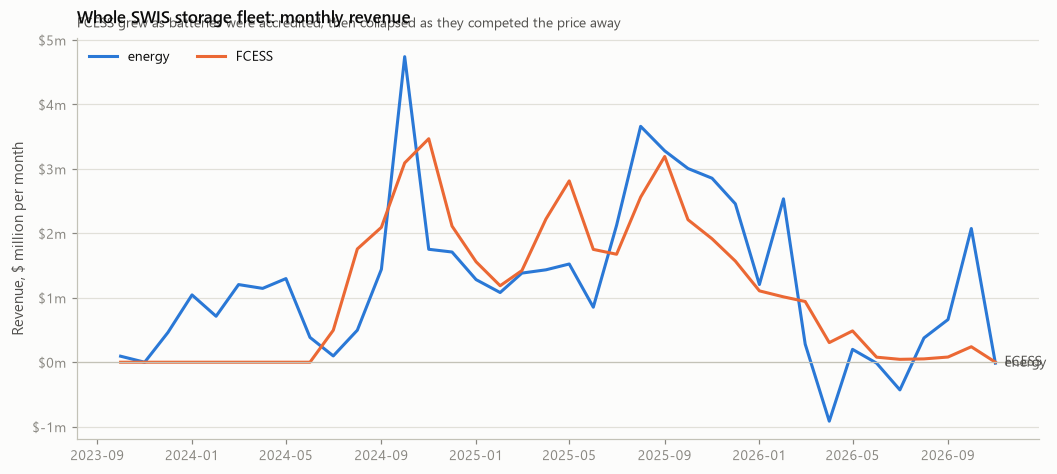

In [13]:
monthly = daily.copy()
monthly["month"] = monthly["trading_date"].dt.to_period("M").dt.to_timestamp()
fleet_monthly = monthly.groupby("month")[["energy_revenue", "fcess_revenue"]].sum() / 1e6

fig, ax = viz.figure(9.5, 4.2)
ax.plot(fleet_monthly.index, fleet_monthly["energy_revenue"], color=viz.SERIES[0], label="energy")
ax.plot(fleet_monthly.index, fleet_monthly["fcess_revenue"], color=viz.SERIES[1], label="FCESS")
viz.label_last(ax, fleet_monthly.index[-1], fleet_monthly["energy_revenue"].iloc[-1], "energy", viz.SERIES[0])
viz.label_last(ax, fleet_monthly.index[-1], fleet_monthly["fcess_revenue"].iloc[-1], "FCESS", viz.SERIES[1])

ax.axhline(0, color=viz.AXIS, linewidth=0.8)
viz.money(ax, unit="m")
viz.finish(
    ax,
    "Whole SWIS storage fleet: monthly revenue",
    subtitle="FCESS grew as batteries were accredited, then collapsed as they competed the price away",
    ylabel="Revenue, $ million per month",
)
ax.legend(loc="upper left", ncols=2)
plt.show()